# Library Book Management System
**DAA Mini Project (CIC-311), Project 2, T3 Group 14**

| Roll Number | Name |
|---|---|
| 15015602724 | Utpal Raj |
| 15115602724 | Anvita Sharma |
| 15215602724 | Atharv Tiwari |

Supervisor: Prof. (Dr.) Pinki Nayak

The same code is in `library_core.py`, which the website's server (`server.py`) imports.

**Data structures and algorithms used**
- **Stack (LIFO)**: books that come back are pushed onto a return stack and reshelved from the top.
- **Queue (FIFO)**: every issue request joins a request queue; if a book has no free copy the member joins that book's waitlist queue.
- **Searching**: linear search (partial match on title / author) and binary search (exact title on a sorted catalogue).
- **Sorting**: merge sort, written by hand, keeps the catalogue sorted for binary search.
- **Timestamps**: every issue and return is time-stamped; due dates, overdue books and fines are derived from them.
- **CSV + pandas**: the library state is saved to and loaded from CSV files.
- **Charts**: popular books, borrowing patterns, and measured running time of the algorithms.

## 1. Setup

In [1]:
import os
import random
import time
from dataclasses import dataclass, asdict
from datetime import datetime, timedelta

import pandas as pd

DATA_DIR = "library_data"
LOAN_DAYS = 14           # a book is due 14 days after it is issued
FINE_PER_DAY = 2         # Rs. 2 for every day late
MAX_BOOKS_PER_MEMBER = 3

# notebook only: charts, output folders and a fixed seed for the benchmarks
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
random.seed(14)
FIG_DIR = "figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

## 2. Stack and Queue
Both are written from scratch on top of a singly linked list, so every operation is O(1).
- `Stack`: push and pop at the head.
- `Queue`: enqueue at the tail, dequeue at the head (a `tail` pointer avoids walking the list).

In [2]:
class Node:
    __slots__ = ("data", "next")

    def __init__(self, data, next=None):
        self.data = data
        self.next = next


class Stack:
    """LIFO stack. push / pop / peek are O(1)."""

    def __init__(self):
        self._top = None
        self._size = 0

    def push(self, item):
        self._top = Node(item, self._top)
        self._size += 1

    def pop(self):
        if self.is_empty():
            raise IndexError("pop from empty stack")
        item = self._top.data
        self._top = self._top.next
        self._size -= 1
        return item

    def peek(self):
        if self.is_empty():
            raise IndexError("peek at empty stack")
        return self._top.data

    def is_empty(self):
        return self._top is None

    def __len__(self):
        return self._size

    def to_list(self):
        """Top first."""
        out, cur = [], self._top
        while cur:
            out.append(cur.data)
            cur = cur.next
        return out


class Queue:
    """FIFO queue. enqueue / dequeue / front are O(1)."""

    def __init__(self):
        self._head = None
        self._tail = None
        self._size = 0

    def enqueue(self, item):
        node = Node(item)
        if self._tail is None:
            self._head = self._tail = node
        else:
            self._tail.next = node
            self._tail = node
        self._size += 1

    def dequeue(self):
        if self.is_empty():
            raise IndexError("dequeue from empty queue")
        item = self._head.data
        self._head = self._head.next
        if self._head is None:
            self._tail = None
        self._size -= 1
        return item

    def front(self):
        if self.is_empty():
            raise IndexError("front of empty queue")
        return self._head.data

    def is_empty(self):
        return self._head is None

    def __len__(self):
        return self._size

    def to_list(self):
        """Front first."""
        out, cur = [], self._head
        while cur:
            out.append(cur.data)
            cur = cur.next
        return out


# quick self-test
s = Stack()
for x in [1, 2, 3]:
    s.push(x)
assert s.pop() == 3 and s.peek() == 2 and len(s) == 2

q = Queue()
for x in "ABC":
    q.enqueue(x)
assert q.dequeue() == "A" and q.front() == "B" and len(q) == 2
print("Stack and Queue self-tests passed")

Stack and Queue self-tests passed


## 3. Sorting and searching
- `merge_sort(items, key)`: stable, O(n log n) in every case.
- `linear_search(books, text, field)`: scans every book and returns all partial matches, O(n).
- `binary_search(sorted_books, title)`: exact title lookup on the sorted catalogue, O(log n).
- `prefix_search(sorted_books, prefix)`: binary search for the first title with the prefix, then walks forward, O(log n + k).
- `linear_search_count` and `binary_search_trace`: the same searches, but they also report the comparisons made and every lo / mid / hi step. The frontend uses them to show the algorithm working.

In [3]:
def merge_sort(items, key=lambda x: x):
    if len(items) <= 1:
        return list(items)
    mid = len(items) // 2
    left = merge_sort(items[:mid], key)
    right = merge_sort(items[mid:], key)
    return merge(left, right, key)


def merge(left, right, key):
    out, i, j = [], 0, 0
    while i < len(left) and j < len(right):
        if key(left[i]) <= key(right[j]):     # <= keeps the sort stable
            out.append(left[i]); i += 1
        else:
            out.append(right[j]); j += 1
    out.extend(left[i:])
    out.extend(right[j:])
    return out


def linear_search(books, text, field="title"):
    text = text.lower()
    return [b for b in books if text in getattr(b, field).lower()]


def binary_search(sorted_books, title):
    """Index of the book whose title equals `title` (case-insensitive), or -1."""
    target = title.lower()
    lo, hi = 0, len(sorted_books) - 1
    while lo <= hi:
        mid = (lo + hi) // 2
        mid_title = sorted_books[mid].title.lower()
        if mid_title == target:
            return mid
        if mid_title < target:
            lo = mid + 1
        else:
            hi = mid - 1
    return -1


def lower_bound(sorted_books, prefix):
    """First index whose title is >= prefix."""
    lo, hi = 0, len(sorted_books)
    while lo < hi:
        mid = (lo + hi) // 2
        if sorted_books[mid].title.lower() < prefix:
            lo = mid + 1
        else:
            hi = mid
    return lo


def prefix_search(sorted_books, prefix):
    prefix = prefix.lower()
    i = lower_bound(sorted_books, prefix)
    out = []
    while i < len(sorted_books) and sorted_books[i].title.lower().startswith(prefix):
        out.append(sorted_books[i])
        i += 1
    return out

def linear_search_count(books, text, field="title"):
    """Linear search that also reports how many books it compared."""
    text = text.lower()
    found = [b for b in books if text in getattr(b, field).lower()]
    return found, len(books)


def binary_search_trace(sorted_books, title):
    """Binary search that records every step (lo, mid, hi and the decision) for display."""
    target = title.lower()
    lo, hi, steps = 0, len(sorted_books) - 1, []
    while lo <= hi:
        mid = (lo + hi) // 2
        mid_title = sorted_books[mid].title.lower()
        if mid_title == target:
            steps.append({"lo": lo, "mid": mid, "hi": hi, "title at mid": sorted_books[mid].title, "decision": "found"})
            return mid, steps
        decision = "go right (lo = mid + 1)" if mid_title < target else "go left (hi = mid - 1)"
        steps.append({"lo": lo, "mid": mid, "hi": hi, "title at mid": sorted_books[mid].title, "decision": decision})
        if mid_title < target:
            lo = mid + 1
        else:
            hi = mid - 1
    return -1, steps


def prefix_search_trace(sorted_books, prefix):
    """Prefix search that records the lower-bound binary search steps for display."""
    prefix = prefix.lower()
    lo, hi, steps = 0, len(sorted_books), []
    while lo < hi:
        mid = (lo + hi) // 2
        go_right = sorted_books[mid].title.lower() < prefix
        steps.append({"lo": lo, "mid": mid, "hi": hi, "title at mid": sorted_books[mid].title,
                      "decision": "go right (lo = mid + 1)" if go_right else "go left (hi = mid)"})
        if go_right:
            lo = mid + 1
        else:
            hi = mid
    out, i = [], lo
    while i < len(sorted_books) and sorted_books[i].title.lower().startswith(prefix):
        out.append(sorted_books[i])
        i += 1
    return out, steps


assert merge_sort([5, 2, 9, 1, 5, 6]) == [1, 2, 5, 5, 6, 9]
print("merge_sort self-test passed")

merge_sort self-test passed


## 4. Data model
Three entities, which match the ER diagram in the report:
**Book**, **Member** and **Transaction** (one row per issue, completed when the book is returned).

In [4]:
@dataclass
class Book:
    book_id: str
    title: str
    author: str
    genre: str
    year: int
    total_copies: int
    available_copies: int


@dataclass
class Member:
    member_id: str
    name: str
    email: str
    joined: str


@dataclass
class Transaction:
    txn_id: str
    book_id: str
    member_id: str
    request_time: datetime
    issue_time: datetime
    due_time: datetime
    return_time: datetime = None
    fine: int = 0

    @property
    def is_open(self):
        return self.return_time is None

## 5. The Library
`Library` ties everything together.

| Operation | What happens | Structure | Cost |
|---|---|---|---|
| `request_issue` | request joins the end of the request queue | Queue | O(1) |
| `process_requests` | requests are served first-come-first-served; if no copy is free the member joins that book's waitlist | Queue | O(r) for r requests |
| `return_book` | timestamp, fine, book pushed onto the return stack | Stack | O(1) + O(t) to find the open transaction |
| `reshelve` | top of the return stack goes back on the shelf; the first waiting member gets it | Stack + Queue | O(1) per book |
| `search_*` | linear / binary / prefix search | Searching | O(n) / O(log n) |

In [5]:
class Library:
    def __init__(self):
        self.books = {}              # book_id -> Book
        self.members = {}            # member_id -> Member
        self.transactions = []       # all issues, in time order
        self.request_queue = Queue() # (member_id, book_id, request_time)
        self.waitlists = {}          # book_id -> Queue of (member_id, request_time)
        self.return_stack = Stack()  # (book_id, return_time) waiting to be reshelved
        self.sorted_catalogue = []   # books sorted by title, for binary search
        self.log = []                # human-readable event log
        self._txn_counter = 0

    # ---------- catalogue ----------
    def add_book(self, book):
        self.books[book.book_id] = book
        self.waitlists.setdefault(book.book_id, Queue())
        self._resort()

    def remove_book(self, book_id):
        book = self.books.get(book_id)
        if book is None:
            raise KeyError(f"No book {book_id}")
        if book.available_copies < book.total_copies:
            raise ValueError("Cannot remove a book that is issued")
        del self.books[book_id]
        del self.waitlists[book_id]
        self._resort()

    def add_member(self, member):
        self.members[member.member_id] = member

    def _resort(self):
        self.sorted_catalogue = merge_sort(list(self.books.values()), key=lambda b: b.title.lower())

    # ---------- searching ----------
    def search_title(self, text):
        return linear_search(self.sorted_catalogue, text, "title")

    def search_author(self, text):
        return linear_search(self.sorted_catalogue, text, "author")

    def find_exact_title(self, title):
        i = binary_search(self.sorted_catalogue, title)
        return self.sorted_catalogue[i] if i >= 0 else None

    def search_prefix(self, prefix):
        return prefix_search(self.sorted_catalogue, prefix)

    # ---------- issuing ----------
    def books_held_by(self, member_id):
        return [t for t in self.transactions if t.member_id == member_id and t.is_open]

    def request_issue(self, member_id, book_id, when):
        if member_id not in self.members:
            raise KeyError(f"No member {member_id}")
        if book_id not in self.books:
            raise KeyError(f"No book {book_id}")
        self.request_queue.enqueue((member_id, book_id, when))
        self._log(when, f"{member_id} requested {self.books[book_id].title!r} (queue size {len(self.request_queue)})")

    def process_requests(self, when):
        """Serve the whole request queue in FIFO order. Returns how many books were issued."""
        issued = 0
        while not self.request_queue.is_empty():
            member_id, book_id, requested = self.request_queue.dequeue()
            book = self.books[book_id]
            if len(self.books_held_by(member_id)) >= MAX_BOOKS_PER_MEMBER:
                self._log(when, f"refused {member_id}: already holds {MAX_BOOKS_PER_MEMBER} books")
            elif any(t.book_id == book_id for t in self.books_held_by(member_id)):
                self._log(when, f"refused {member_id}: already holds {book.title!r}")
            elif book.available_copies > 0:
                self._issue(member_id, book_id, requested, when)
                issued += 1
            elif any(m == member_id for m, _ in self.waitlists[book_id].to_list()):
                self._log(when, f"refused {member_id}: already waiting for {book.title!r}")
            else:
                self.waitlists[book_id].enqueue((member_id, requested))
                self._log(when, f"{member_id} added to waitlist for {book.title!r} (position {len(self.waitlists[book_id])})")
        return issued

    def _issue(self, member_id, book_id, requested, when):
        self._txn_counter += 1
        txn = Transaction(f"T{self._txn_counter:05d}", book_id, member_id,
                          requested, when, when + timedelta(days=LOAN_DAYS))
        self.transactions.append(txn)
        self.books[book_id].available_copies -= 1
        self._log(when, f"issued {self.books[book_id].title!r} to {member_id}, due {txn.due_time:%d %b %Y}")
        return txn

    # ---------- returning ----------
    def return_book(self, member_id, book_id, when):
        txn = next((t for t in self.transactions
                    if t.member_id == member_id and t.book_id == book_id and t.is_open), None)
        if txn is None:
            raise ValueError(f"{member_id} does not hold {book_id}")
        txn.return_time = when
        late_days = max(0, (when.date() - txn.due_time.date()).days)
        txn.fine = late_days * FINE_PER_DAY
        self.return_stack.push((book_id, when))
        msg = f"{member_id} returned {self.books[book_id].title!r}"
        if txn.fine:
            msg += f", {late_days} days late, fine Rs.{txn.fine}"
        self._log(when, msg + f" (return stack size {len(self.return_stack)})")
        return txn

    def reshelve(self, when, count=None):
        """Pop books off the return stack (top first) and put them back on the shelf.
        If someone is waiting for that book, the first one in its waitlist gets it."""
        done = 0
        while not self.return_stack.is_empty() and (count is None or done < count):
            book_id, _ = self.return_stack.pop()
            book = self.books[book_id]
            book.available_copies += 1
            done += 1
            self._log(when, f"reshelved {book.title!r}")
            wl = self.waitlists[book_id]
            while not wl.is_empty() and book.available_copies > 0:
                member_id, requested = wl.dequeue()
                held = self.books_held_by(member_id)
                if len(held) < MAX_BOOKS_PER_MEMBER and all(t.book_id != book_id for t in held):
                    self._issue(member_id, book_id, requested, when)
                else:
                    self._log(when, f"skipped {member_id} in waitlist for {book.title!r}: limit reached")
        return done

    # ---------- reports ----------
    def overdue(self, now):
        return [t for t in self.transactions if t.is_open and t.due_time < now]

    def _log(self, when, text):
        self.log.append((when, text))

    # ---------- CSV ----------
    def save_csv(self, folder=DATA_DIR):
        pd.DataFrame([asdict(b) for b in self.books.values()]).to_csv(f"{folder}/books.csv", index=False)
        pd.DataFrame([asdict(m) for m in self.members.values()]).to_csv(f"{folder}/members.csv", index=False)
        pd.DataFrame([asdict(t) for t in self.transactions]).to_csv(f"{folder}/transactions.csv", index=False)
        waiting = [{"book_id": b, "position": i + 1, "member_id": m, "request_time": r}
                   for b, q in self.waitlists.items() for i, (m, r) in enumerate(q.to_list())]
        pd.DataFrame(waiting, columns=["book_id", "position", "member_id", "request_time"]) \
            .to_csv(f"{folder}/waitlists.csv", index=False)
        stack = [{"position_from_top": i + 1, "book_id": b, "return_time": r}
                 for i, (b, r) in enumerate(self.return_stack.to_list())]
        pd.DataFrame(stack, columns=["position_from_top", "book_id", "return_time"]) \
            .to_csv(f"{folder}/return_stack.csv", index=False)

    @classmethod
    def load_csv(cls, folder=DATA_DIR):
        lib = cls()
        for r in pd.read_csv(f"{folder}/books.csv").to_dict("records"):
            lib.books[r["book_id"]] = Book(**r)
            lib.waitlists[r["book_id"]] = Queue()
        lib._resort()
        for r in pd.read_csv(f"{folder}/members.csv").to_dict("records"):
            lib.add_member(Member(**r))
        tx = pd.read_csv(f"{folder}/transactions.csv",
                         parse_dates=["request_time", "issue_time", "due_time", "return_time"])
        for r in tx.to_dict("records"):
            r["return_time"] = None if pd.isna(r["return_time"]) else r["return_time"].to_pydatetime()
            for k in ("request_time", "issue_time", "due_time"):
                r[k] = r[k].to_pydatetime()
            lib.transactions.append(Transaction(**r))
        lib._txn_counter = len(lib.transactions)
        wl = pd.read_csv(f"{folder}/waitlists.csv", parse_dates=["request_time"]).sort_values(["book_id", "position"])
        for r in wl.to_dict("records"):
            lib.waitlists[r["book_id"]].enqueue((r["member_id"], r["request_time"].to_pydatetime()))
        st = pd.read_csv(f"{folder}/return_stack.csv", parse_dates=["return_time"])
        for r in reversed(st.sort_values("position_from_top").to_dict("records")):   # push bottom first
            lib.return_stack.push((r["book_id"], r["return_time"].to_pydatetime()))
        return lib

## 6. Sample data
60 books and 25 members.

In [6]:
BOOKS = [
    ("Introduction to Algorithms", "Thomas H. Cormen", "Computer Science", 2009, 5),
    ("The Algorithm Design Manual", "Steven S. Skiena", "Computer Science", 2008, 3),
    ("Algorithms", "Robert Sedgewick", "Computer Science", 2011, 3),
    ("Data Structures Using C", "Reema Thareja", "Computer Science", 2014, 4),
    ("Fundamentals of Computer Algorithms", "Ellis Horowitz", "Computer Science", 2008, 4),
    ("Let Us C", "Yashavant Kanetkar", "Computer Science", 2017, 4),
    ("Clean Code", "Robert C. Martin", "Computer Science", 2008, 2),
    ("The Pragmatic Programmer", "Andrew Hunt", "Computer Science", 1999, 2),
    ("Computer Networks", "Andrew S. Tanenbaum", "Computer Science", 2010, 3),
    ("Operating System Concepts", "Abraham Silberschatz", "Computer Science", 2018, 3),
    ("Database System Concepts", "Abraham Silberschatz", "Computer Science", 2019, 3),
    ("Artificial Intelligence: A Modern Approach", "Stuart Russell", "Computer Science", 2020, 2),
    ("Discrete Mathematics and Its Applications", "Kenneth H. Rosen", "Mathematics", 2018, 3),
    ("Higher Engineering Mathematics", "B. S. Grewal", "Mathematics", 2017, 5),
    ("Linear Algebra Done Right", "Sheldon Axler", "Mathematics", 2015, 2),
    ("Concepts of Physics", "H. C. Verma", "Science", 2017, 4),
    ("A Brief History of Time", "Stephen Hawking", "Science", 1988, 2),
    ("The Selfish Gene", "Richard Dawkins", "Science", 1976, 2),
    ("Cosmos", "Carl Sagan", "Science", 1980, 1),
    ("Sapiens", "Yuval Noah Harari", "History", 2011, 3),
    ("The Discovery of India", "Jawaharlal Nehru", "History", 1946, 2),
    ("India After Gandhi", "Ramachandra Guha", "History", 2007, 2),
    ("Guns, Germs, and Steel", "Jared Diamond", "History", 1997, 1),
    ("Wings of Fire", "A. P. J. Abdul Kalam", "Biography", 1999, 3),
    ("The Story of My Experiments with Truth", "M. K. Gandhi", "Biography", 1927, 2),
    ("Steve Jobs", "Walter Isaacson", "Biography", 2011, 2),
    ("Long Walk to Freedom", "Nelson Mandela", "Biography", 1994, 1),
    ("Atomic Habits", "James Clear", "Self-Help", 2018, 3),
    ("Deep Work", "Cal Newport", "Self-Help", 2016, 2),
    ("Thinking, Fast and Slow", "Daniel Kahneman", "Self-Help", 2011, 2),
    ("The Psychology of Money", "Morgan Housel", "Self-Help", 2020, 2),
    ("Ikigai", "Hector Garcia", "Self-Help", 2016, 2),
    ("Pride and Prejudice", "Jane Austen", "Fiction", 1813, 2),
    ("1984", "George Orwell", "Fiction", 1949, 3),
    ("Animal Farm", "George Orwell", "Fiction", 1945, 2),
    ("To Kill a Mockingbird", "Harper Lee", "Fiction", 1960, 2),
    ("The Great Gatsby", "F. Scott Fitzgerald", "Fiction", 1925, 2),
    ("The Alchemist", "Paulo Coelho", "Fiction", 1988, 3),
    ("The Guide", "R. K. Narayan", "Fiction", 1958, 2),
    ("Malgudi Days", "R. K. Narayan", "Fiction", 1943, 2),
    ("Godan", "Munshi Premchand", "Fiction", 1936, 2),
    ("The God of Small Things", "Arundhati Roy", "Fiction", 1997, 1),
    ("Midnight's Children", "Salman Rushdie", "Fiction", 1981, 1),
    ("The White Tiger", "Aravind Adiga", "Fiction", 2008, 2),
    ("Gitanjali", "Rabindranath Tagore", "Poetry", 1910, 1),
    ("Brave New World", "Aldous Huxley", "Fiction", 1932, 1),
    ("The Hobbit", "J. R. R. Tolkien", "Fiction", 1937, 2),
    ("Harry Potter and the Philosopher's Stone", "J. K. Rowling", "Fiction", 1997, 3),
    ("The Little Prince", "Antoine de Saint-Exupery", "Fiction", 1943, 1),
    ("Crime and Punishment", "Fyodor Dostoevsky", "Fiction", 1866, 1),
    ("War and Peace", "Leo Tolstoy", "Fiction", 1869, 1),
    ("The Old Man and the Sea", "Ernest Hemingway", "Fiction", 1952, 1),
    ("Rich Dad Poor Dad", "Robert Kiyosaki", "Finance", 1997, 2),
    ("The Intelligent Investor", "Benjamin Graham", "Finance", 1949, 1),
    ("Zero to One", "Peter Thiel", "Business", 2014, 2),
    ("The Lean Startup", "Eric Ries", "Business", 2011, 1),
    ("Head First Java", "Kathy Sierra", "Computer Science", 2005, 2),
    ("Python Crash Course", "Eric Matthes", "Computer Science", 2019, 3),
    ("Hands-On Machine Learning", "Aurelien Geron", "Computer Science", 2019, 2),
    ("Design Patterns", "Erich Gamma", "Computer Science", 1994, 1),
]

FIRST = ["Aarav", "Vivaan", "Aditya", "Ishaan", "Kabir", "Riya", "Ananya", "Diya", "Saanvi", "Meera",
         "Rohan", "Karan", "Arjun", "Neha", "Pooja", "Tanvi", "Yash", "Manav", "Sneha", "Kavya",
         "Dev", "Nikhil", "Priya", "Aisha", "Harsh"]
LAST = ["Sharma", "Verma", "Gupta", "Singh", "Mehta", "Jain", "Kapoor", "Reddy", "Nair", "Bansal"]


def build_library(seed=14):
    rng = random.Random(seed)
    lib = Library()
    for i, (title, author, genre, year, copies) in enumerate(BOOKS, start=1):
        lib.add_book(Book(f"B{i:03d}", title, author, genre, year, copies, copies))
    for i, first in enumerate(FIRST, start=1):
        last = rng.choice(LAST)
        lib.add_member(Member(f"M{i:03d}", f"{first} {last}",
                              f"{first.lower()}.{last.lower()}@example.com", "2025-07-01"))
    return lib

library = build_library()
print(f"{len(library.books)} books, {sum(b.total_copies for b in library.books.values())} copies, "
      f"{len(library.members)} members")
pd.DataFrame([asdict(b) for b in library.sorted_catalogue]).head(10)

60 books, 133 copies, 25 members


,book_id,title,author,genre,year,total_copies,available_copies
0,B034,1984,George Orwell,Fiction,1949,3,3
1,B017,A Brief History of Time,Stephen Hawking,Science,1988,2,2
2,B003,Algorithms,Robert Sedgewick,Computer Science,2011,3,3
3,B035,Animal Farm,George Orwell,Fiction,1945,2,2
4,B012,Artificial Intelligence: A Modern Approach,Stuart Russell,Computer Science,2020,2,2
5,B028,Atomic Habits,James Clear,Self-Help,2018,3,3
6,B046,Brave New World,Aldous Huxley,Fiction,1932,1,1
7,B007,Clean Code,Robert C. Martin,Computer Science,2008,2,2
8,B009,Computer Networks,Andrew S. Tanenbaum,Computer Science,2010,3,3
9,B016,Concepts of Physics,H. C. Verma,Science,2017,4,4


## 7. Step-by-step demo
A small scenario that shows the queue and stack working:
1. Four members ask for *Cosmos* (only 1 copy) and one asks for *1984*.
2. Requests are served in FIFO order; the rest wait in the *Cosmos* waitlist.
3. *Cosmos* comes back late, so a fine is charged and it is pushed on the return stack.
4. Reshelving pops it off the stack and hands it straight to the next member in the waitlist.

In [7]:
demo = build_library()
t0 = datetime(2025, 8, 1, 10, 0)
cosmos = demo.find_exact_title("Cosmos").book_id
nineteen = demo.find_exact_title("1984").book_id

for k, m in enumerate(["M001", "M002", "M003", "M004"]):
    demo.request_issue(m, cosmos, t0 + timedelta(minutes=k))
demo.request_issue("M005", nineteen, t0 + timedelta(minutes=5))

print("Request queue (front first):", [(m, demo.books[b].title) for m, b, _ in demo.request_queue.to_list()])
demo.process_requests(t0 + timedelta(minutes=10))
print("Cosmos waitlist (front first):", [m for m, _ in demo.waitlists[cosmos].to_list()])

demo.return_book("M005", nineteen, t0 + timedelta(days=3))
demo.return_book("M001", cosmos, t0 + timedelta(days=17))          # 3 days late
print("Return stack (top first):", [demo.books[b].title for b, _ in demo.return_stack.to_list()])

demo.reshelve(t0 + timedelta(days=17, hours=1))
print("Cosmos waitlist after reshelving:", [m for m, _ in demo.waitlists[cosmos].to_list()])

print("\nEvent log")
for when, text in demo.log:
    print(f"  {when:%d %b %H:%M}  {text}")

Request queue (front first): [('M001', 'Cosmos'), ('M002', 'Cosmos'), ('M003', 'Cosmos'), ('M004', 'Cosmos'), ('M005', '1984')]
Cosmos waitlist (front first): ['M002', 'M003', 'M004']
Return stack (top first): ['Cosmos', '1984']
Cosmos waitlist after reshelving: ['M003', 'M004']

Event log
  01 Aug 10:00  M001 requested 'Cosmos' (queue size 1)
  01 Aug 10:01  M002 requested 'Cosmos' (queue size 2)
  01 Aug 10:02  M003 requested 'Cosmos' (queue size 3)
  01 Aug 10:03  M004 requested 'Cosmos' (queue size 4)
  01 Aug 10:05  M005 requested '1984' (queue size 5)
  01 Aug 10:10  issued 'Cosmos' to M001, due 15 Aug 2025
  01 Aug 10:10  M002 added to waitlist for 'Cosmos' (position 1)
  01 Aug 10:10  M003 added to waitlist for 'Cosmos' (position 2)
  01 Aug 10:10  M004 added to waitlist for 'Cosmos' (position 3)
  01 Aug 10:10  issued '1984' to M005, due 15 Aug 2025
  04 Aug 10:00  M005 returned '1984' (return stack size 1)
  18 Aug 10:00  M001 returned 'Cosmos', 3 days late, fine Rs.6 (return

## 8. Searching the catalogue

In [8]:
print("Linear search, title contains 'the':")
for b in library.search_title("the")[:6]:
    print("   ", b.title)

print("\nLinear search, author contains 'orwell':")
for b in library.search_author("orwell"):
    print("   ", b.title, "-", b.author)

print("\nPrefix search (binary search + scan), titles starting with 'the a':")
for b in library.search_prefix("the a"):
    print("   ", b.title)

print("\nBinary search, exact title 'Wings of Fire':", library.find_exact_title("Wings of Fire"))
print("Binary search, exact title 'Unknown Book':", library.find_exact_title("Unknown Book"))

Linear search, title contains 'the':
    Discrete Mathematics and Its Applications
    Harry Potter and the Philosopher's Stone
    Higher Engineering Mathematics
    The Alchemist
    The Algorithm Design Manual
    The Discovery of India

Linear search, author contains 'orwell':
    1984 - George Orwell
    Animal Farm - George Orwell

Prefix search (binary search + scan), titles starting with 'the a':
    The Alchemist
    The Algorithm Design Manual

Binary search, exact title 'Wings of Fire': Book(book_id='B024', title='Wings of Fire', author='A. P. J. Abdul Kalam', genre='Biography', year=1999, total_copies=3, available_copies=3)
Binary search, exact title 'Unknown Book': None


## 9. Simulating one semester (90 days)
Each day a few members request books (popular books are picked more often), requests are served,
some books come back (a few of them late) and the return stack is cleared at closing time.

In [9]:
START = datetime(2025, 8, 1, 9, 0)


def simulate(lib, days=90, start=START, seed=14):
    """Simulate `days` days of library use. Returns the time at the end of the simulation.
    Each day a few members request books (popular books are picked more often), requests are
    served, some books come back (a few of them late) and the return stack is cleared."""
    rng = random.Random(seed)
    book_ids = list(lib.books)
    members = list(lib.members)
    weights = [1 / (i + 1) ** 0.7 for i in range(len(book_ids))]    # a few books are much more popular
    rng.shuffle(weights)
    for day in range(days):
        today = start + timedelta(days=day)
        for _ in range(rng.randint(3, 9)):
            m = rng.choice(members)
            b = rng.choices(book_ids, weights)[0]
            lib.request_issue(m, b, today + timedelta(minutes=rng.randint(0, 480)))
        lib.process_requests(today + timedelta(hours=9))

        for t in [t for t in lib.transactions if t.is_open]:
            held = (today - t.issue_time).days
            if held >= 3 and rng.random() < (0.12 if held < LOAN_DAYS else 0.30):
                lib.return_book(t.member_id, t.book_id, today + timedelta(hours=rng.randint(1, 8)))
        lib.reshelve(today + timedelta(hours=10))
    return start + timedelta(days=days)

NOW = simulate(library, days=90)
done = [t for t in library.transactions if not t.is_open]
print(f"Transactions: {len(library.transactions)}  returned: {len(done)}  still out: {len(library.transactions) - len(done)}")
print(f"Late returns: {sum(t.fine > 0 for t in done)}  fines collected: Rs.{sum(t.fine for t in done)}")
print(f"Overdue right now: {len(library.overdue(NOW))}")
print(f"Members still waiting: {sum(len(q) for q in library.waitlists.values())}")

Transactions: 337  returned: 304  still out: 33
Late returns: 66  fines collected: Rs.396
Overdue right now: 2
Members still waiting: 29


## 10. Save to CSV and load back

In [10]:
library.save_csv()
print(sorted(os.listdir(DATA_DIR)))

reloaded = Library.load_csv()
assert len(reloaded.books) == len(library.books)
assert len(reloaded.transactions) == len(library.transactions)
assert [b.title for b in reloaded.sorted_catalogue] == [b.title for b in library.sorted_catalogue]
assert reloaded.waitlists.keys() == library.waitlists.keys()
assert all(len(reloaded.waitlists[k]) == len(library.waitlists[k]) for k in library.waitlists)
print("Reloaded library matches the saved one")

tx = pd.read_csv(f"{DATA_DIR}/transactions.csv", parse_dates=["request_time", "issue_time", "due_time", "return_time"])
tx.head(8)

['benchmark.csv', 'books.csv', 'members.csv', 'return_stack.csv', 'transactions.csv', 'waitlists.csv']
Reloaded library matches the saved one


,txn_id,book_id,member_id,request_time,issue_time,due_time,return_time,fine
0,T00001,B026,M007,2025-08-01 11:24:00,2025-08-01 18:00:00,2025-08-15 18:00:00,2025-08-13 13:00:00,0
1,T00002,B018,M017,2025-08-01 10:02:00,2025-08-01 18:00:00,2025-08-15 18:00:00,2025-08-18 16:00:00,6
2,T00003,B021,M003,2025-08-01 10:00:00,2025-08-01 18:00:00,2025-08-15 18:00:00,2025-08-11 17:00:00,0
3,T00004,B011,M001,2025-08-01 12:30:00,2025-08-01 18:00:00,2025-08-15 18:00:00,2025-08-17 10:00:00,4
4,T00005,B038,M004,2025-08-01 14:00:00,2025-08-01 18:00:00,2025-08-15 18:00:00,2025-08-19 13:00:00,8
5,T00006,B026,M003,2025-08-01 14:50:00,2025-08-01 18:00:00,2025-08-15 18:00:00,2025-08-08 14:00:00,0
6,T00007,B027,M006,2025-08-01 12:53:00,2025-08-01 18:00:00,2025-08-15 18:00:00,2025-08-06 16:00:00,0
7,T00008,B048,M020,2025-08-02 11:11:00,2025-08-02 18:00:00,2025-08-16 18:00:00,2025-08-08 16:00:00,0


## 11. Reports

In [11]:
books_df = pd.read_csv(f"{DATA_DIR}/books.csv")
tx = tx.merge(books_df[["book_id", "title", "genre"]], on="book_id")
tx["days_kept"] = (tx["return_time"] - tx["issue_time"]).dt.days
tx["wait_hours"] = (tx["issue_time"] - tx["request_time"]).dt.total_seconds() / 3600

print("Overdue books on", f"{NOW:%d %b %Y}")
overdue = pd.DataFrame([{"member": t.member_id, "title": library.books[t.book_id].title,
                         "due": f"{t.due_time:%d %b}", "days late": (NOW - t.due_time).days,
                         "fine so far (Rs.)": (NOW - t.due_time).days * FINE_PER_DAY}
                        for t in library.overdue(NOW)]).sort_values("days late", ascending=False)
overdue.head(10)

Overdue books on 30 Oct 2025


,member,title,due,days late,fine so far (Rs.)
0,M001,Godan,24 Oct,5,10
1,M012,Crime and Punishment,29 Oct,0,0


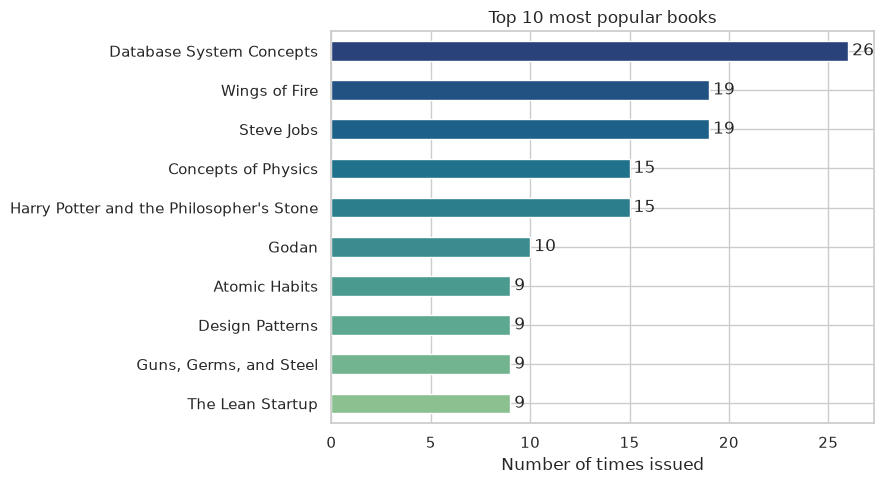

In [12]:
popular = tx["title"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
popular.plot.barh(ax=ax, color=sns.color_palette("crest", len(popular)))
ax.set_xlabel("Number of times issued")
ax.set_ylabel("")
ax.set_title("Top 10 most popular books")
for i, v in enumerate(popular.values):
    ax.text(v + 0.2, i, str(v), va="center")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/popular_books.png", dpi=200)
plt.show()

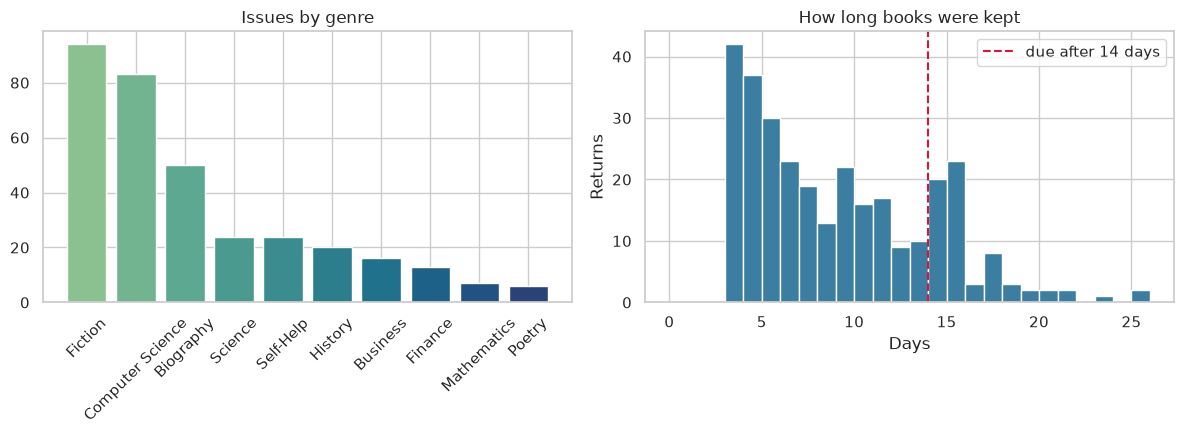

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

genre = tx["genre"].value_counts()
axes[0].bar(genre.index, genre.values, color=sns.color_palette("crest", len(genre)))
axes[0].set_title("Issues by genre")
axes[0].tick_params(axis="x", rotation=45)

kept = tx["days_kept"].dropna()
axes[1].hist(kept, bins=range(0, int(kept.max()) + 2), color="#3b7ea1", edgecolor="white")
axes[1].axvline(LOAN_DAYS, color="crimson", linestyle="--", label=f"due after {LOAN_DAYS} days")
axes[1].set_title("How long books were kept")
axes[1].set_xlabel("Days")
axes[1].set_ylabel("Returns")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/genre_and_duration.png", dpi=200)
plt.show()

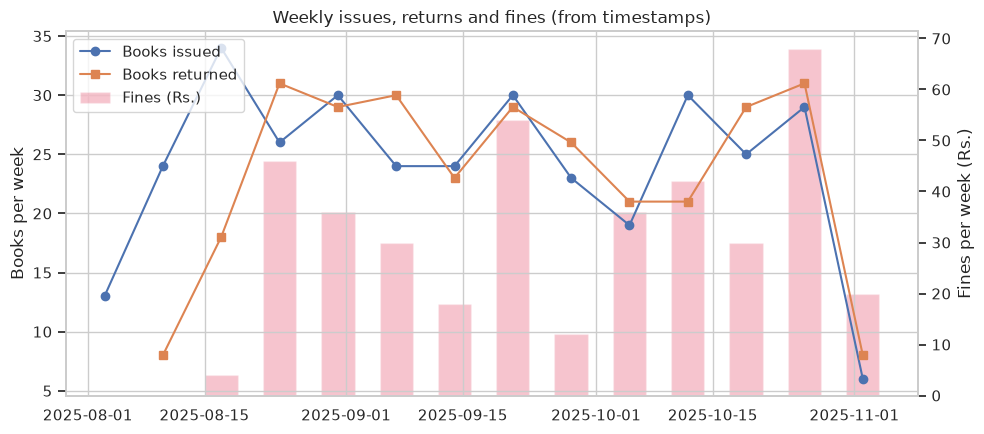

In [14]:
daily = tx.set_index("issue_time").resample("W")["txn_id"].count()
returns = tx.dropna(subset=["return_time"]).set_index("return_time").resample("W")["txn_id"].count()
fines = tx.dropna(subset=["return_time"]).set_index("return_time").resample("W")["fine"].sum()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily.index, daily.values, marker="o", label="Books issued")
ax.plot(returns.index, returns.values, marker="s", label="Books returned")
ax.set_ylabel("Books per week")
ax2 = ax.twinx()
ax2.bar(fines.index, fines.values, width=4, alpha=0.25, color="crimson", label="Fines (Rs.)")
ax2.set_ylabel("Fines per week (Rs.)")
ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1)   # keep the lines in front of the bars
ax.patch.set_visible(False)
ax.set_title("Weekly issues, returns and fines (from timestamps)")
lines = ax.get_legend_handles_labels()
bars = ax2.get_legend_handles_labels()
ax.legend(lines[0] + bars[0], lines[1] + bars[1], loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/weekly_activity.png", dpi=200)
plt.show()

## 12. Measuring the algorithms
To back up the complexity analysis, every algorithm is timed on catalogues of growing size.
Each search is repeated many times and the average is taken, so the numbers are stable.

In [15]:
def make_books(n):
    return [Book(f"X{i:06d}", f"Title {random.random():.12f}", f"Author {i % 997}", "Test", 2000, 1, 1)
            for i in range(n)]


def avg_time(fn, repeats):
    start = time.perf_counter()
    for _ in range(repeats):
        fn()
    return (time.perf_counter() - start) / repeats


SIZES = [1_000, 5_000, 10_000, 25_000, 50_000, 100_000]
rows = []
for n in SIZES:
    data = make_books(n)
    t_sort = avg_time(lambda: merge_sort(data, key=lambda b: b.title), 1)
    srt = merge_sort(data, key=lambda b: b.title)
    targets = [random.choice(srt).title for _ in range(50)]
    t_lin = avg_time(lambda: [next(b for b in srt if b.title == t) for t in targets], 3) / len(targets)
    t_bin = avg_time(lambda: [binary_search(srt, t) for t in targets], 400) / len(targets)
    st, qu = Stack(), Queue()
    for i in range(n):                       # fill both structures with n items first
        st.push(i)
        qu.enqueue(i)
    # best of 20 runs of 1000 operations: the minimum filters out pauses caused by other programs
    t_push = min(avg_time(lambda: [st.push(1) for _ in range(1000)], 1) for _ in range(20)) / 1000
    t_enq = min(avg_time(lambda: [qu.enqueue(1) for _ in range(1000)], 1) for _ in range(20)) / 1000
    rows.append({"n": n, "merge sort (ms)": t_sort * 1e3, "linear search (us)": t_lin * 1e6,
                 "binary search (us)": t_bin * 1e6, "stack push (us)": t_push * 1e6,
                 "queue enqueue (us)": t_enq * 1e6})

bench = pd.DataFrame(rows)
bench.to_csv(f"{DATA_DIR}/benchmark.csv", index=False)
bench.round(3)

,n,merge sort (ms),linear search (us),binary search (us),stack push (us),queue enqueue (us)
0,1000,2.281,10.698,1.485,0.195,0.202
1,5000,11.744,95.610,1.979,0.180,0.202
2,10000,26.021,170.844,2.067,0.178,0.189
3,25000,76.870,462.735,2.207,0.184,0.193
4,50000,157.892,2686.509,2.356,0.174,0.183
5,100000,379.770,9969.269,2.437,0.195,0.202


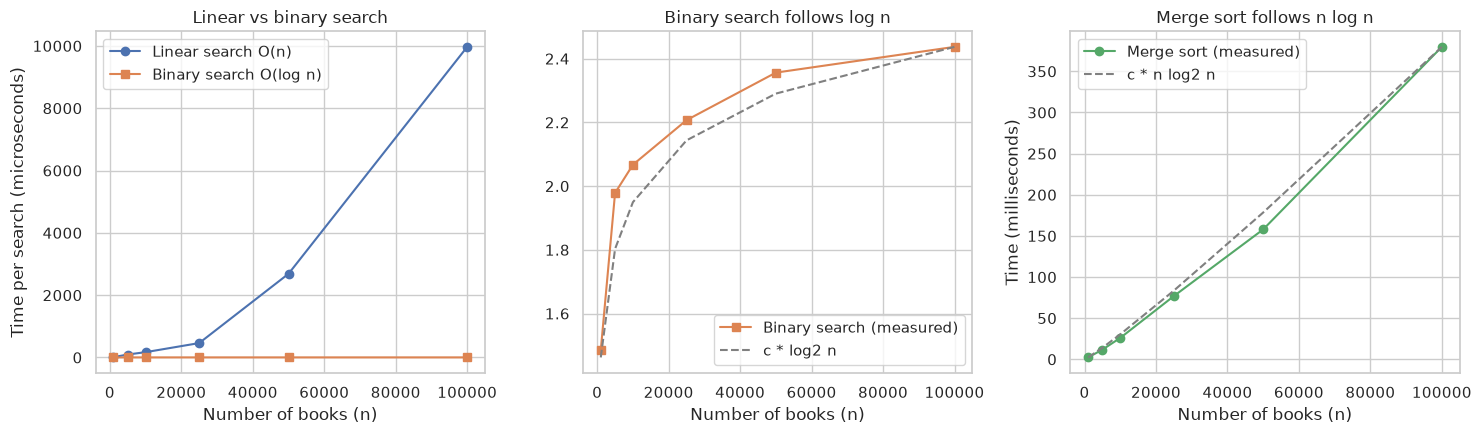

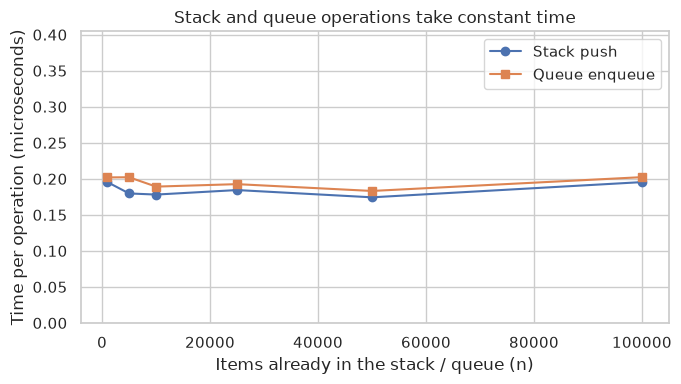

In [16]:
import math

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(bench["n"], bench["linear search (us)"], marker="o", label="Linear search O(n)")
axes[0].plot(bench["n"], bench["binary search (us)"], marker="s", label="Binary search O(log n)")
axes[0].set_xlabel("Number of books (n)")
axes[0].set_ylabel("Time per search (microseconds)")
axes[0].set_title("Linear vs binary search")
axes[0].legend()

axes[1].plot(bench["n"], bench["binary search (us)"], marker="s", color="C1", label="Binary search (measured)")
c = bench["binary search (us)"].iloc[-1] / math.log2(bench["n"].iloc[-1])
axes[1].plot(bench["n"], [c * math.log2(n) for n in bench["n"]], "--", color="gray", label="c * log2 n")
axes[1].set_xlabel("Number of books (n)")
axes[1].set_title("Binary search follows log n")
axes[1].legend()

axes[2].plot(bench["n"], bench["merge sort (ms)"], marker="o", color="C2", label="Merge sort (measured)")
c = bench["merge sort (ms)"].iloc[-1] / (bench["n"].iloc[-1] * math.log2(bench["n"].iloc[-1]))
axes[2].plot(bench["n"], [c * n * math.log2(n) for n in bench["n"]], "--", color="gray", label="c * n log2 n")
axes[2].set_xlabel("Number of books (n)")
axes[2].set_ylabel("Time (milliseconds)")
axes[2].set_title("Merge sort follows n log n")
axes[2].legend()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/benchmark.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bench["n"], bench["stack push (us)"], marker="o", label="Stack push")
ax.plot(bench["n"], bench["queue enqueue (us)"], marker="s", label="Queue enqueue")
ax.set_ylim(0, max(bench["stack push (us)"].max(), bench["queue enqueue (us)"].max()) * 2)
ax.set_xlabel("Items already in the stack / queue (n)")
ax.set_ylabel("Time per operation (microseconds)")
ax.set_title("Stack and queue operations take constant time")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/stack_queue_constant.png", dpi=200)
plt.show()

## 13. Interactive menu
Set `RUN_MENU = True` and run the cell to use the library from the keyboard.

In [17]:
RUN_MENU = False


def menu(lib):
    actions = {
        "1": "Search by title", "2": "Search by author", "3": "Request a book",
        "4": "Process request queue", "5": "Return a book", "6": "Reshelve returned books",
        "7": "Show overdue books", "8": "Save to CSV", "0": "Exit",
    }
    while True:
        print()
        for k, v in actions.items():
            print(f"  {k}. {v}")
        choice = input("Choice: ").strip()
        now = datetime.now()
        try:
            if choice == "1":
                for b in lib.search_title(input("Title contains: ")):
                    print(f"  {b.book_id}  {b.title}  ({b.available_copies}/{b.total_copies} free)")
            elif choice == "2":
                for b in lib.search_author(input("Author contains: ")):
                    print(f"  {b.book_id}  {b.title} - {b.author}")
            elif choice == "3":
                lib.request_issue(input("Member id: ").strip(), input("Book id: ").strip(), now)
                print("  Added to request queue")
            elif choice == "4":
                print(f"  {lib.process_requests(now)} books issued")
            elif choice == "5":
                t = lib.return_book(input("Member id: ").strip(), input("Book id: ").strip(), now)
                print(f"  Returned. Fine: Rs.{t.fine}")
            elif choice == "6":
                print(f"  {lib.reshelve(now)} books reshelved")
            elif choice == "7":
                for t in lib.overdue(now):
                    print(f"  {t.member_id}  {lib.books[t.book_id].title}  due {t.due_time:%d %b}")
            elif choice == "8":
                lib.save_csv()
                print("  Saved")
            elif choice == "0":
                break
        except (KeyError, ValueError) as e:
            print("  Error:", e)


if RUN_MENU:
    menu(library)